<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L04_classification_nn_tl/01ADS_L04_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lecture 04: Classification – metrics, thresholds, calibration and models

Lecture workbook on supervised classification of tabular data: how a classification problem differs from the regression problems of Lecture 03, how to read a confusion matrix and the many names of its derived quantities, how to work with scores and thresholds (ROC and precision–recall curves), what calibration means, and how the usual model families (linear models, trees, forests, gradient boosting, neural networks) behave on the same data and when to use which.

The running example is the IBM HR employee attrition data set (1 470 employees, 35 columns, 16 % of employees left the company). The second notebook of this lecture, `01ADS_L04_Transfer_Learning.ipynb`, moves from tabular data to images.

## Schedule for today's lecture
- From regression to classification
  - Decision functions, scores and probabilities
  - Binary, multiclass and multilabel problems
- The confusion matrix and its vocabulary
  - Accuracy, precision, recall, specificity, F1, balanced accuracy, MCC
  - The same quantities under different names
  - Which mistake hurts more? (a quiz)
  - The accuracy paradox on imbalanced data
- Scores, thresholds and curves
  - Guess who leaves
  - ROC curve and AUC (with an animated construction of the curve), precision–recall curve and average precision
  - Choosing a threshold: F1, Youden's J, misclassification costs; the threshold and the costs as sliders
  - Proper scoring rules: log-loss and Brier score
- Calibration
  - Three weather forecasters with the same ranking
  - Reliability diagrams, Platt scaling and isotonic regression
- Models on the attrition data
  - One preprocessing pipeline, stratified k-fold cross-validation
  - Logistic regression, decision tree, random forest, XGBoost and a PyTorch MLP
  - Threshold tuning on out-of-fold predictions, final check on the test set
  - What drives attrition: logistic regression coefficients and SHAP values of XGBoost
- Which model when
  - A multiclass example: handwritten digits

## 0. Setup

All libraries used here are part of a standard Colab runtime; `xgboost`, `torch` and `shap` are installed only when missing. Data files are read from the lecture folder when the notebook runs from a clone of the repository and from GitHub otherwise.

In [1]:
import importlib, subprocess, sys

for package in ["xgboost", "torch", "shap"]:
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [2]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_moons
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures/L04_classification_nn_tl"


def resource(relative_path):
    # local file when the notebook runs inside a clone of the repository, GitHub URL otherwise
    local = Path(relative_path)
    return local if local.exists() else f"{RAW}/{relative_path}"

## 1. From regression to classification

In Lecture 03 the target $y$ was a real number (house value) and a model was a function $\hat f: \mathcal{X} \to \mathbb{R}$ judged by RMSE or $R^2$. In classification the target is a **label** from a finite set $\{c_1, \dots, c_K\}$. Almost every classifier nevertheless works with numbers internally:

1. it computes a **score** $s(x)$ for each class (a logit, a distance to a hyperplane, a vote count, a leaf frequency),
2. optionally it maps scores to **probabilities** $\hat p(c \mid x)$ (logistic function, softmax, averaging over trees),
3. it turns probabilities into a **decision** with a rule, in the binary case $\hat y = 1 \iff \hat p(1 \mid x) \ge t$ with a threshold $t$ that is $0.5$ by default.

Keeping the three stages apart is the key idea of this notebook: the quality of the scores (ranking), the quality of the probabilities (calibration) and the quality of the decisions (confusion matrix) are three different things, measured by three different families of metrics.

| Problem | Target | Typical output layer / rule | Examples |
|---|---|---|---|
| binary | one of two classes | one probability, threshold | churn, fraud, disease yes/no |
| multiclass | exactly one of $K$ classes | $K$ probabilities summing to 1 (softmax), argmax | digit recognition, document topic |
| multilabel | any subset of $K$ labels | $K$ independent probabilities, $K$ thresholds | tags of an image, symptoms of a patient |

Most of today's material is about the binary case; Section 6 says what changes for multiclass problems.

### Decision boundaries of four model families

Before touching real data, a two-dimensional toy problem shows how differently the model families partition the input space.

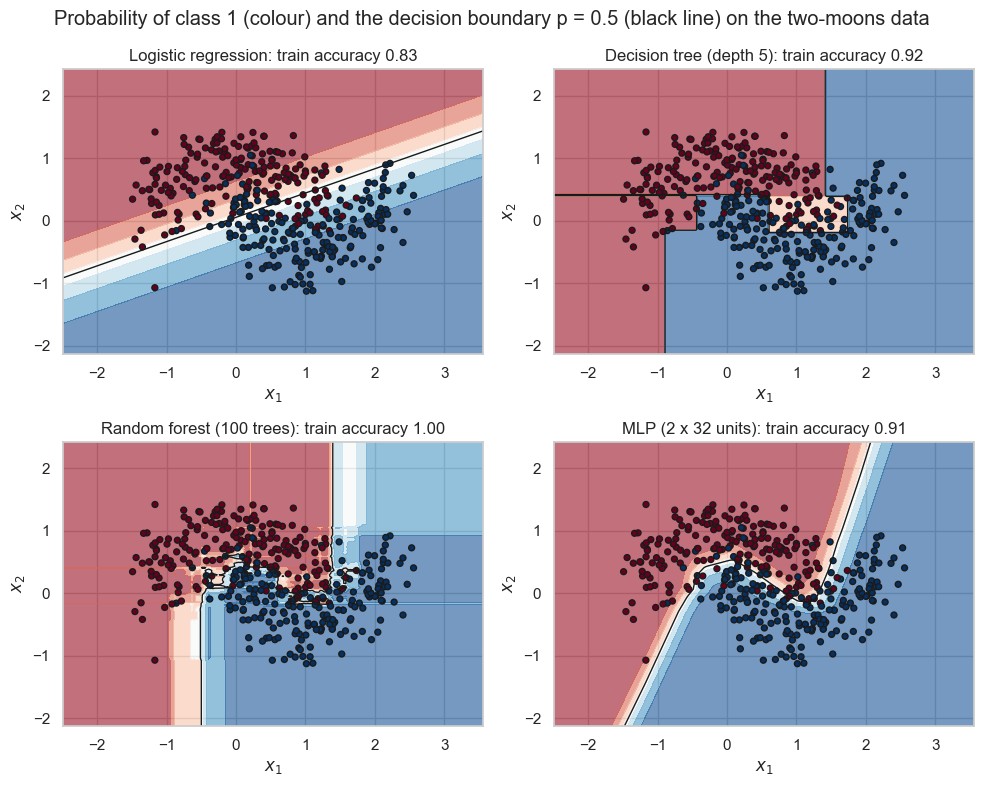

In [3]:
X_toy, y_toy = make_moons(n_samples=400, noise=0.3, random_state=SEED)

toy_models = {
    "Logistic regression": LogisticRegression(),
    "Decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "MLP (2 x 32 units)": MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=2000, random_state=SEED),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, model) in zip(axes.ravel(), toy_models.items()):
    model.fit(X_toy, y_toy)
    disp = DecisionBoundaryDisplay.from_estimator(
        model, X_toy, response_method="predict_proba", cmap="RdBu", alpha=0.6, ax=ax, grid_resolution=200
    )
    ax.contour(disp.xx0, disp.xx1, disp.response, levels=[0.5], colors="k", linewidths=1)  # p = 0.5
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="RdBu", edgecolor="k", s=18)
    ax.set_title(f"{name}: train accuracy {model.score(X_toy, y_toy):.2f}")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
fig.suptitle("Probability of class 1 (colour) and the decision boundary p = 0.5 (black line) on the two-moons data")
plt.tight_layout()

The colour shows $\hat p(1 \mid x)$, the black line the default decision boundary $\hat p = 0.5$.

- **Logistic regression** can only draw a straight line (a hyperplane in general); its probabilities change smoothly.
- A **decision tree** cuts the plane into axis-parallel rectangles; probabilities are piecewise constant and jump at the cuts.
- A **random forest** averages many trees: boundaries become smoother and probabilities more graded, but far from the data the forest is still confident (little extrapolation awareness).
- An **MLP** learns a smooth, curved boundary; with enough units it can fit almost anything, which is both its strength and its risk.

Training accuracy is of course not the quantity of interest; the rest of the notebook is about measuring generalisation properly.

## 2. The confusion matrix and its vocabulary

For a binary problem we call one class **positive** (the event we are looking for: the employee leaves, the transaction is fraudulent, the patient is ill) and the other **negative**. Comparing predictions with the truth gives four counts:

| | predicted negative (0) | predicted positive (1) |
|---|---|---|
| **actually negative** ($N = TN + FP$) | true negative $TN$ | false positive $FP$ (false alarm, type I error) |
| **actually positive** ($P = TP + FN$) | false negative $FN$ (miss, type II error) | true positive $TP$ |

The table uses the scikit-learn layout (classes in the order 0, 1), so in every confusion matrix plotted below $TN$ is top-left and $TP$ bottom-right. Everything else is a ratio of these four numbers:

$$
\text{accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \qquad
\text{precision (PPV)} = \frac{TP}{TP + FP}, \qquad
\text{recall (sensitivity, TPR)} = \frac{TP}{TP + FN}
$$

$$
\text{specificity (TNR)} = \frac{TN}{TN + FP}, \qquad
\text{FPR} = \frac{FP}{FP + TN} = 1 - \text{TNR}, \qquad
\text{FNR} = \frac{FN}{FN + TP} = 1 - \text{TPR}
$$

$$
F_1 = 2\,\frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}} = \frac{2\,TP}{2\,TP + FP + FN}, \qquad
\text{balanced accuracy} = \frac{\text{TPR} + \text{TNR}}{2}
$$

$$
\text{MCC} = \frac{TP \cdot TN - FP \cdot FN}{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}} \in [-1, 1]
$$

Precision answers *"when the model raises an alarm, how often is it right?"*, recall answers *"how many of the real positives does the model catch?"*. The $F_1$ score is their harmonic mean, so it is low whenever either of the two is low. Balanced accuracy and Matthews' correlation coefficient (MCC) use all four cells and are therefore robust to class imbalance; MCC is the Pearson correlation between the true and the predicted 0/1 labels.

![Precision and recall](https://raw.githubusercontent.com/francji1/01ADS/main/lectures/L04_classification_nn_tl/pics/Precisionrecall.png)

### The same quantity, four names

The vocabulary differs between communities, which causes real confusion in practice. All of these refer to the same four counts:

| Quantity | Statistics (hypothesis testing) | Medicine, diagnostics | Machine learning | Information retrieval |
|---|---|---|---|---|
| $TP / (TP + FN)$ | power, $1 - \beta$ | sensitivity | recall, true positive rate (TPR), hit rate | recall |
| $TN / (TN + FP)$ | $1 - \alpha$ | specificity | true negative rate (TNR), selectivity | – |
| $FP / (FP + TN)$ | $\alpha$, type I error rate, significance level | false alarm rate | false positive rate (FPR) | fall-out |
| $FN / (FN + TP)$ | $\beta$, type II error rate | miss rate | false negative rate (FNR) | – |
| $TP / (TP + FP)$ | – | positive predictive value (PPV) | precision | precision |
| $TN / (TN + FN)$ | – | negative predictive value (NPV) | – | – |
| $FP / (FP + TP)$ | false discovery rate (FDR) | – | $1 - $ precision | – |
| $(TP + TN) / (P + N)$ | – | diagnostic accuracy | accuracy | – |

Note the difference between the *row-wise* rates (sensitivity, specificity: conditioned on the truth, independent of the class balance) and the *column-wise* rates (precision, NPV: conditioned on the prediction, strongly dependent on the class balance, i.e. on the prevalence of the positive class).

### Which mistake hurts more?

Before any formula: decide for each situation which class is "positive", which of the two errors is worse, and therefore which metric you would watch and in which direction you would move the threshold.

| Situation | Positive class | Which error is worse? | Metric to watch, threshold direction |
|---|---|---|---|
| screening test for a serious but treatable disease | ? | ? | ? |
| spam filter on your mailbox | ? | ? | ? |
| credit-card fraud detection that blocks the card | ? | ? | ? |
| predicting which employees will leave (this notebook) | ? | ? | ? |

<details>
<summary>Answers</summary>

| Situation | Positive class | Worse error | Consequence |
|---|---|---|---|
| screening test | disease present | a **miss** (false negative): the patient goes home untreated | maximise recall (sensitivity), **lower** the threshold; a positive result is followed by a more specific confirmatory test |
| spam filter | spam | a **false alarm** (false positive): an important e-mail disappears into the spam folder | maximise precision, **raise** the threshold; a spam message in the inbox costs a click |
| fraud detection | fraudulent transaction | depends on the costs: a miss loses money, a false alarm annoys a customer and costs a phone call | explicit costs per error, threshold from the cost ratio; both error types matter |
| employee attrition | employee leaves | usually a **miss**: a leaving employee is expensive, a retention conversation is cheap | recall at an acceptable precision, **lower** the threshold; Section 3 quantifies this |

</details>

### The attrition data and the accuracy paradox

We split the data once into a training part (80 %) and a test part (20 %), stratified so that both parts contain the same share of positives. The test part is put aside and touched only at the very end of the notebook; everything else (model selection, threshold tuning, calibration) happens with cross-validation inside the training part, exactly as in Lecture 03.

In [4]:
df = pd.read_csv(resource("data/attrition.csv"))

TARGET = "Attrition"
DROP = ["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"]  # identifiers and constants

X = df.drop(columns=[TARGET] + DROP)
y = (df[TARGET] == "Yes").astype(int)

categorical = X.columns[X.dtypes == object].tolist()
numeric = [c for c in X.columns if c not in categorical]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"rows: {len(df)}, numeric features: {len(numeric)}, categorical features: {len(categorical)}")
print(f"positives (Attrition = Yes): {y.mean():.1%} overall, {y_train.mean():.1%} in train, {y_test.mean():.1%} in test")
print(f"train / test sizes: {len(X_train)} / {len(X_test)}")
df.head(3)

rows: 1470, numeric features: 23, categorical features: 7
positives (Attrition = Yes): 16.1% overall, 16.2% in train, 16.0% in test
train / test sizes: 1176 / 294


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


In [5]:
preprocessor = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ],
    sparse_threshold=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_pipeline(model):
    return Pipeline([("prep", preprocessor), ("model", model)])

A classifier that always predicts the majority class ("nobody leaves") is the classification analogue of the mean baseline of Lecture 03. With 16 % positives it reaches 84 % accuracy without learning anything, and it misses every single employee who leaves. This is the **accuracy paradox**: on imbalanced data accuracy is dominated by the majority class and says little about the thing we actually care about.

In [6]:
dummy = make_pipeline(DummyClassifier(strategy="most_frequent"))
logreg = make_pipeline(LogisticRegression(max_iter=2000))

# out-of-fold predictions on the training part: every training row is predicted by a model that has not seen it
# (cross_val_predict clones and fits the pipeline inside every fold, the objects above stay unfitted)
pred_dummy = cross_val_predict(dummy, X_train, y_train, cv=cv)
pred_logreg = cross_val_predict(logreg, X_train, y_train, cv=cv)

print("Majority-class baseline (cross-validated on the training part)")
print(classification_report(y_train, pred_dummy, target_names=["stays", "leaves"], zero_division=0))
print("Logistic regression, default threshold 0.5")
print(classification_report(y_train, pred_logreg, target_names=["stays", "leaves"]))

Majority-class baseline (cross-validated on the training part)
              precision    recall  f1-score   support

       stays       0.84      1.00      0.91       986
      leaves       0.00      0.00      0.00       190

    accuracy                           0.84      1176
   macro avg       0.42      0.50      0.46      1176
weighted avg       0.70      0.84      0.76      1176

Logistic regression, default threshold 0.5
              precision    recall  f1-score   support

       stays       0.90      0.98      0.94       986
      leaves       0.79      0.44      0.57       190

    accuracy                           0.89      1176
   macro avg       0.84      0.71      0.75      1176
weighted avg       0.88      0.89      0.88      1176



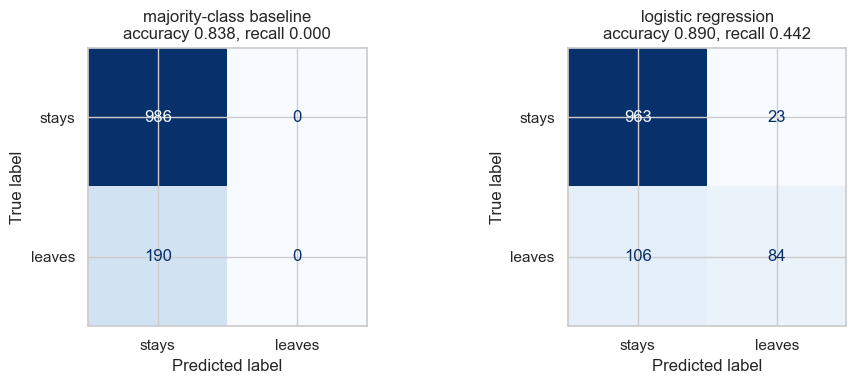

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, {"majority-class baseline": pred_dummy, "logistic regression": pred_logreg}.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_train, pred, display_labels=["stays", "leaves"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_train, pred):.3f}, recall {recall_score(y_train, pred):.3f}")
plt.tight_layout()

`classification_report` prints precision, recall and $F_1$ per class together with two averages, `macro` (unweighted mean over classes) and `weighted` (weighted by class size); the `micro` average (computed from the pooled counts) equals the accuracy for single-label problems and is therefore printed as the `accuracy` line.

The formulas above are simple enough to implement by hand, which is a good way to make sure the vocabulary is understood. The function below reproduces the scikit-learn metrics from the four counts.

In [8]:
def metrics_from_counts(tn, fp, fn, tp):
    p, n = tp + fn, tn + fp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / p
    specificity = tn / n
    mcc_den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {
        "accuracy": (tp + tn) / (p + n),
        "precision (PPV)": precision,
        "recall (TPR, sensitivity)": recall,
        "specificity (TNR)": specificity,
        "FPR (type I)": fp / n,
        "FNR (type II)": fn / p,
        "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "balanced accuracy": (recall + specificity) / 2,
        "MCC": (tp * tn - fp * fn) / mcc_den if mcc_den else 0.0,
    }


tn, fp, fn, tp = confusion_matrix(y_train, pred_logreg).ravel()
by_hand = pd.Series(metrics_from_counts(tn, fp, fn, tp), name="by hand")
by_sklearn = pd.Series(
    {
        "accuracy": accuracy_score(y_train, pred_logreg),
        "precision (PPV)": precision_score(y_train, pred_logreg),
        "recall (TPR, sensitivity)": recall_score(y_train, pred_logreg),
        "specificity (TNR)": recall_score(y_train, pred_logreg, pos_label=0),
        "FPR (type I)": 1 - recall_score(y_train, pred_logreg, pos_label=0),
        "FNR (type II)": 1 - recall_score(y_train, pred_logreg),
        "F1": f1_score(y_train, pred_logreg),
        "balanced accuracy": balanced_accuracy_score(y_train, pred_logreg),
        "MCC": matthews_corrcoef(y_train, pred_logreg),
    },
    name="scikit-learn",
)
pd.concat([by_hand, by_sklearn], axis=1)

,by hand,scikit-learn
accuracy,0.890,0.890
precision (PPV),0.785,0.785
"recall (TPR, sensitivity)",0.442,0.442
specificity (TNR),0.977,0.977
FPR (type I),0.023,0.023
FNR (type II),0.558,0.558
F1,0.566,0.566
balanced accuracy,0.709,0.709
MCC,0.536,0.536


Logistic regression at the default threshold catches less than half of the employees who leave (recall 0.44) although its accuracy is well above the baseline. Whether that is good or bad depends on what the predictions are used for, which brings us to thresholds.

## 3. Scores, thresholds and curves

`predict` hides a decision: scikit-learn classifiers return the class with the highest probability, i.e. for binary problems they apply the threshold $t = 0.5$ to `predict_proba`. The threshold is not a property of the model but of the *decision*, and it should be chosen for the application. Lowering $t$ trades precision for recall; raising it does the opposite. All quantities of Section 2 are therefore functions of $t$.

We study the out-of-fold probabilities of the (unweighted) logistic regression.

*Before running: where does the accuracy curve end for $t \to 1$, and why?*

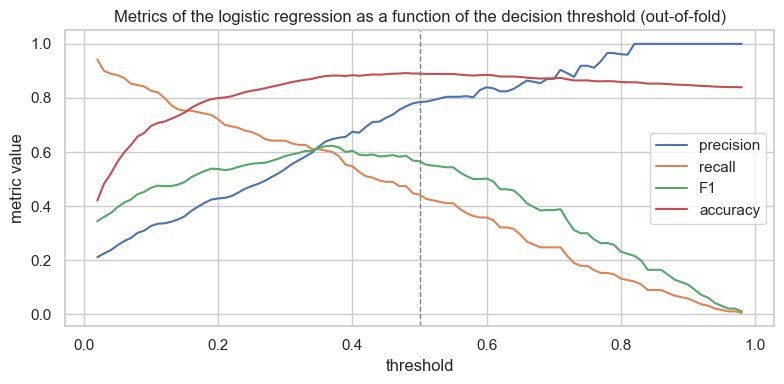

In [9]:
prob_logreg = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.linspace(0.02, 0.98, 97)
curve = pd.DataFrame(
    {
        "threshold": thresholds,
        "precision": [precision_score(y_train, prob_logreg >= t, zero_division=0) for t in thresholds],
        "recall": [recall_score(y_train, prob_logreg >= t) for t in thresholds],
        "F1": [f1_score(y_train, prob_logreg >= t) for t in thresholds],
        "accuracy": [accuracy_score(y_train, prob_logreg >= t) for t in thresholds],
    }
).set_index("threshold")

ax = curve.plot(figsize=(8, 4))
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_ylabel("metric value")
ax.set_title("Metrics of the logistic regression as a function of the decision threshold (out-of-fold)")
plt.tight_layout()

For $t \to 1$ nobody is flagged and the accuracy curve ends at 0.84, the majority-class baseline again, while $F_1$ peaks near $t = 0.37$: the two metrics would choose very different thresholds.

### Guess who leaves

Six employees from the training part, without the target column. Three of them left the company. Which three? Decide before running the next cell.

In [10]:
demo_rng = np.random.default_rng(1)   # separate generator so that the rest of the notebook is unaffected
leavers = demo_rng.choice(np.flatnonzero(y_train.values == 1), 3, replace=False)
stayers = demo_rng.choice(np.flatnonzero(y_train.values == 0), 3, replace=False)
quiz_idx = demo_rng.permutation(np.concatenate([leavers, stayers]))
quiz_cols = ["Age", "JobRole", "OverTime", "MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion",
             "BusinessTravel", "DistanceFromHome", "JobSatisfaction"]

quiz = X_train.iloc[quiz_idx][quiz_cols].copy()
quiz.index = [f"employee {letter}" for letter in "ABCDEF"]
quiz

,Age,JobRole,OverTime,MonthlyIncome,YearsAtCompany,YearsSinceLastPromotion,BusinessTravel,DistanceFromHome,JobSatisfaction
employee A,22,Laboratory Technician,Yes,2398,1,0,Travel_Rarely,8,1
employee B,58,Manager,Yes,17875,1,0,Travel_Rarely,21,4
employee C,50,Sales Executive,No,6728,6,0,Travel_Frequently,1,3
employee D,40,Research Scientist,No,3319,9,4,Travel_Rarely,24,4
employee E,32,Laboratory Technician,No,2176,6,0,Travel_Rarely,2,1
employee F,34,Laboratory Technician,No,5346,7,0,Travel_Frequently,9,1


In [11]:
reveal = quiz[["OverTime", "JobRole", "MonthlyIncome", "YearsAtCompany"]].copy()
reveal.insert(0, "left the company", np.where(y_train.values[quiz_idx] == 1, "yes", "no"))
reveal.insert(1, "P(leaves), out-of-fold", prob_logreg[quiz_idx].round(2))
reveal.sort_values("P(leaves), out-of-fold", ascending=False)

,left the company,"P(leaves), out-of-fold",OverTime,JobRole,MonthlyIncome,YearsAtCompany
employee E,no,0.38,No,Laboratory Technician,2176,6
employee A,yes,0.33,Yes,Laboratory Technician,2398,1
employee F,yes,0.11,No,Laboratory Technician,5346,7
employee D,no,0.05,No,Research Scientist,3319,9
employee B,no,0.03,Yes,Manager,17875,1
employee C,yes,0.03,No,Sales Executive,6728,6


The model ranks the six employees better than a coin, but it is far from certain about any of them: the probabilities of the leavers and the stayers overlap. A ROC-AUC of 0.84 is a decent ranking, not clairvoyance. That is exactly why we work with probabilities and choose a threshold deliberately instead of trusting a hard 0/1 prediction.

### ROC curve and AUC

The **receiver operating characteristic** (ROC) curve plots the true positive rate against the false positive rate for every threshold. It depends only on the *ranking* of the scores, not on their scale, so it compares models independently of the threshold choice and of calibration.

The **area under the ROC curve** (ROC-AUC) has a simple probabilistic meaning: it is the probability that a randomly chosen positive example receives a higher score than a randomly chosen negative one,

$$
\text{AUC} = \Pr\big(s(x^+) > s(x^-)\big),
$$

which is also the normalised Mann–Whitney $U$ statistic. A random classifier has AUC $0.5$, a perfect ranking AUC $1$. The cell below checks the interpretation by sampling pairs.

*Before running: will the Monte-Carlo estimate from random pairs match `roc_auc_score`?*

In [12]:
pos = prob_logreg[y_train.values == 1]
neg = prob_logreg[y_train.values == 0]
pairs = 200_000
sampled = rng.choice(pos, pairs) > rng.choice(neg, pairs)
print(f"ROC-AUC via roc_auc_score      : {roc_auc_score(y_train, prob_logreg):.4f}")
print(f"P(score(pos) > score(neg)) : {sampled.mean():.4f}  (Monte Carlo, {pairs:,} random pairs)")

ROC-AUC via roc_auc_score      : 0.8379
P(score(pos) > score(neg)) : 0.8383  (Monte Carlo, 200,000 random pairs)


### How the ROC curve is built

Every threshold is one point of the ROC curve. The animation sweeps the threshold from 1 down to 0 over the two
score distributions (employees who stayed and employees who left). At $t = 1$ nobody is flagged, so TPR = FPR = 0; as
the threshold moves left it first catches mostly true leavers (the curve rises steeply), then more and more stayers
as well (the curve flattens and moves right), until at $t = 0$ everybody is flagged and TPR = FPR = 1. The curve is
the trace of the red point; the AUC is the area it encloses with the horizontal axis.

In [13]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fpr_all, tpr_all, thr_all = roc_curve(y_train, prob_logreg)
sweep = np.linspace(1.0, 0.0, 31)
score_bins = np.linspace(0, 1, 31)

fig, (ax_hist, ax_roc) = plt.subplots(1, 2, figsize=(10, 4), dpi=80)   # 80 dpi keeps the embedded animation small


def draw_frame(k):
    t = sweep[k]
    ax_hist.clear()
    ax_hist.hist(neg, bins=score_bins, alpha=0.6, label="stayed (true negatives)")
    ax_hist.hist(pos, bins=score_bins, alpha=0.6, label="left (true positives)")
    ax_hist.axvline(t, color="k", ls="--", lw=1.5)
    ax_hist.set_xlabel("out-of-fold probability of leaving")
    ax_hist.set_ylabel("employees")
    ax_hist.set_title(f"scores and threshold t = {t:.2f}  (flagged: right of the line)")
    ax_hist.legend(loc="upper right")

    tpr_t, fpr_t = np.mean(pos >= t), np.mean(neg >= t)
    reached = thr_all >= t                       # roc_curve lists thresholds in decreasing order
    ax_roc.clear()
    ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="random ranking")
    ax_roc.plot(fpr_all, tpr_all, color="lightgrey", lw=1)
    ax_roc.plot(fpr_all[reached], tpr_all[reached], color="tab:blue", lw=2, label="ROC curve so far")
    ax_roc.plot(fpr_t, tpr_t, "o", color="tab:red", ms=9, label="current threshold")
    ax_roc.set_xlim(-0.02, 1.02)
    ax_roc.set_ylim(-0.02, 1.02)
    ax_roc.set_xlabel("false positive rate (share of stayers flagged)")
    ax_roc.set_ylabel("true positive rate (share of leavers flagged)")
    ax_roc.set_title(f"t = {t:.2f}:  TPR = {tpr_t:.2f},  FPR = {fpr_t:.2f}")
    ax_roc.legend(loc="lower right")


roc_animation = FuncAnimation(fig, draw_frame, frames=len(sweep), interval=400)
plt.close(fig)
HTML(roc_animation.to_jshtml())

### Precision–recall curve and average precision

The **precision–recall (PR) curve** plots precision against recall for every threshold. Unlike the ROC curve it ignores true negatives, which makes it much more sensitive to the performance on the rare positive class: with 16 % positives a model can have an excellent-looking ROC curve while its precision at useful recall levels is poor. The area under the PR curve is usually reported as **average precision** (AP), the precision averaged over the recall levels at which it changes,

$$
\text{AP} = \sum_k (R_k - R_{k-1})\, P_k .
$$

The baseline of the PR curve is the prevalence of positives (here $0.16$), the baseline of the ROC curve is the diagonal. On imbalanced data prefer PR-AUC (AP) for model comparison and ROC-AUC as a complementary, prevalence-independent view (Saito and Rehmsmeier, 2015).

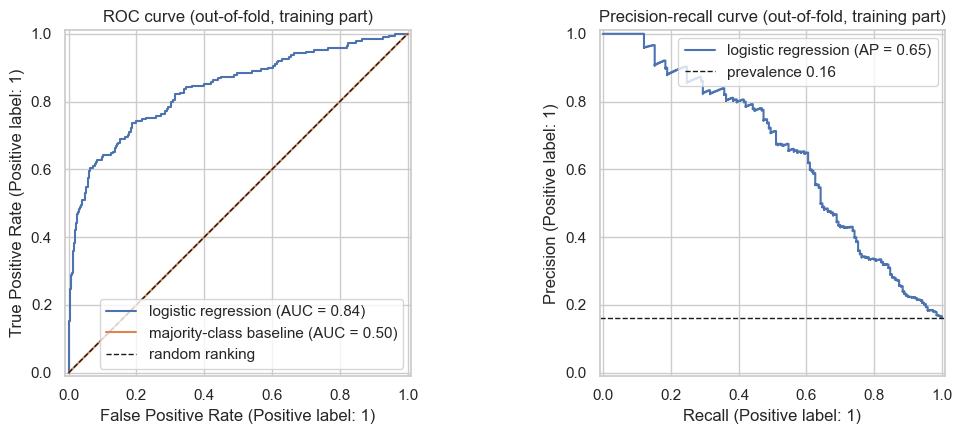

In [14]:
prob_dummy = cross_val_predict(dummy, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, prob in {"logistic regression": prob_logreg, "majority-class baseline": prob_dummy}.items():
    RocCurveDisplay.from_predictions(y_train, prob, name=name, ax=axes[0])
# the PR curve of a constant score is just the prevalence line, so only the model is drawn in the right panel
PrecisionRecallDisplay.from_predictions(y_train, prob_logreg, name="logistic regression", ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random ranking")
axes[0].set_title("ROC curve (out-of-fold, training part)")
axes[1].axhline(y_train.mean(), color="k", ls="--", lw=1, label=f"prevalence {y_train.mean():.2f}")
axes[1].set_title("Precision-recall curve (out-of-fold, training part)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout()

### Choosing the threshold

Three common recipes, all computed on out-of-fold (or validation) predictions, never on the test set:

1. **maximise $F_1$** (or another summary metric) over the threshold grid,
2. **Youden's $J$** $= \text{TPR} - \text{FPR}$, the point of the ROC curve farthest from the diagonal, treats both error types as equally important,
3. **minimise expected cost** with explicit costs $c_{FP}$ and $c_{FN}$. For attrition a false negative (an employee leaves unexpectedly) is typically far more expensive than a false positive (an unnecessary retention conversation); below $c_{FN} = 5\,c_{FP}$.

The cost-based rule is the most honest one because it forces the business question into the open. With calibrated probabilities (Section 4) it has a closed form: predict positive whenever $\hat p \ge c_{FP} / (c_{FP} + c_{FN})$, here $1/6 \approx 0.17$.

In [15]:
def counts_at(y_true, prob, thresholds):
    # TP, FP, FN for every threshold at once (a row is flagged when prob >= threshold)
    y_true = np.asarray(y_true)
    pos, neg = np.sort(prob[y_true == 1]), np.sort(prob[y_true == 0])
    tp = len(pos) - np.searchsorted(pos, thresholds, side="left")
    fp = len(neg) - np.searchsorted(neg, thresholds, side="left")
    return tp, fp, len(pos) - tp


def best_threshold(y_true, prob, criterion="f1", cost_fp=1.0, cost_fn=5.0):
    candidates = np.unique(prob)                         # every threshold that changes a decision
    tp, fp, fn = counts_at(y_true, prob, candidates)
    if criterion == "f1":
        return float(candidates[int(np.argmax(2 * tp / (2 * tp + fp + fn)))])
    if criterion == "youden":
        fpr, tpr, thr = roc_curve(y_true, prob)
        return float(thr[np.argmax(tpr - fpr)])
    if criterion == "cost":
        return float(candidates[int(np.argmin(cost_fp * fp + cost_fn * fn))])
    raise ValueError(criterion)


rows = []
for criterion in ["f1", "youden", "cost"]:
    t = best_threshold(y_train, prob_logreg, criterion)
    pred = prob_logreg >= t
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append(
        {
            "criterion": criterion,
            "threshold": t,
            "precision": precision_score(y_train, pred),
            "recall": recall_score(y_train, pred),
            "F1": f1_score(y_train, pred),
            "balanced accuracy": balanced_accuracy_score(y_train, pred),
            "expected cost (1 : 5)": (fp + 5 * fn) / len(y_train),
        }
    )
pred = prob_logreg >= 0.5
tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
rows.append(
    {
        "criterion": "default 0.5",
        "threshold": 0.5,
        "precision": precision_score(y_train, pred),
        "recall": recall_score(y_train, pred),
        "F1": f1_score(y_train, pred),
        "balanced accuracy": balanced_accuracy_score(y_train, pred),
        "expected cost (1 : 5)": (fp + 5 * fn) / len(y_train),
    }
)
pd.DataFrame(rows).set_index("criterion")

,threshold,precision,recall,F1,balanced accuracy,expected cost (1 : 5)
criterion,,,,,,
f1,0.368,0.650,0.605,0.627,0.771,0.372
youden,0.193,0.431,0.737,0.544,0.775,0.370
cost,0.193,0.431,0.737,0.544,0.775,0.370
default 0.5,0.500,0.785,0.442,0.566,0.709,0.470


Compared with the default threshold, every data-driven rule lowers the threshold, raises the recall from 0.44 to 0.60 ($F_1$) or 0.74 (Youden, cost) and reduces the expected cost; the price is lower precision. Which row is "best" is a business decision, not a statistical one.

The cost-optimal threshold found by search (0.19) is close to the closed-form value $1/6 \approx 0.17$ of the previous cell. That is no coincidence: the rule assumes calibrated probabilities, and Section 4 will show that the plain logistic regression is calibrated. For a model whose probabilities are shifted (class weights, Section 5) the two would disagree, and only the search is right.

### The threshold and the costs as sliders

The function below shows the whole trade-off for one threshold $t$ and one pair of costs: the confusion matrix at $t$, the precision / recall / $F_1$ curves with $t$ marked, and the expected cost per employee as a function of the threshold with its minimum. The dash-dotted line is the closed-form rule $t = c_{FP} / (c_{FP} + c_{FN})$, which is optimal for calibrated probabilities.

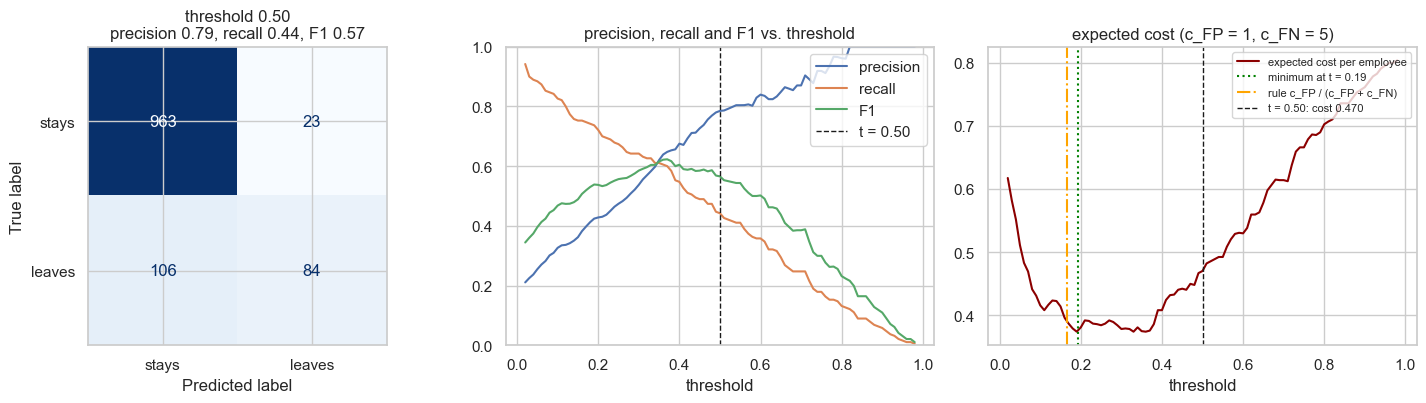

In [16]:
def show_threshold(t=0.5, cost_fp=1.0, cost_fn=5.0):
    grid = np.linspace(0.02, 0.98, 97)
    tp_g, fp_g, fn_g = counts_at(y_train, prob_logreg, grid)
    prec = np.where(tp_g + fp_g > 0, tp_g / np.maximum(tp_g + fp_g, 1), 0.0)
    rec = tp_g / (tp_g + fn_g)
    f1s = 2 * tp_g / (2 * tp_g + fp_g + fn_g)
    costs = (cost_fp * fp_g + cost_fn * fn_g) / len(y_train)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_train, prob_logreg >= t).ravel()
    cost_t = (cost_fp * fp_ + cost_fn * fn_) / len(y_train)
    p_t, r_t = precision_score(y_train, prob_logreg >= t, zero_division=0), recall_score(y_train, prob_logreg >= t)
    f_t = f1_score(y_train, prob_logreg >= t)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    ConfusionMatrixDisplay(np.array([[tn_, fp_], [fn_, tp_]]), display_labels=["stays", "leaves"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False
    )
    axes[0].set_title(f"threshold {t:.2f}\nprecision {p_t:.2f}, recall {r_t:.2f}, F1 {f_t:.2f}")
    axes[1].plot(grid, prec, label="precision")
    axes[1].plot(grid, rec, label="recall")
    axes[1].plot(grid, f1s, label="F1")
    axes[1].axvline(t, color="k", ls="--", lw=1, label=f"t = {t:.2f}")
    axes[1].set_xlabel("threshold")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("precision, recall and F1 vs. threshold")
    axes[1].legend(loc="upper right")
    axes[2].plot(grid, costs, color="darkred", label="expected cost per employee")
    best_t = best_threshold(y_train, prob_logreg, "cost", cost_fp, cost_fn)   # exact search over the scores
    axes[2].axvline(best_t, color="green", ls=":", lw=1.5, label=f"minimum at t = {best_t:.2f}")
    axes[2].axvline(cost_fp / (cost_fp + cost_fn), color="orange", ls="-.", lw=1.5, label="rule c_FP / (c_FP + c_FN)")
    axes[2].axvline(t, color="k", ls="--", lw=1, label=f"t = {t:.2f}: cost {cost_t:.3f}")
    axes[2].set_xlabel("threshold")
    axes[2].set_title(f"expected cost (c_FP = {cost_fp:g}, c_FN = {cost_fn:g})")
    axes[2].legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()


show_threshold(0.5, 1.0, 5.0)

In [17]:
# interactive version (works in Colab and Jupyter): move the sliders and watch precision and recall trade,
# and watch the cost-optimal threshold move when the cost ratio changes
try:
    from ipywidgets import FloatSlider, interact

    interact(
        show_threshold,
        t=FloatSlider(value=0.5, min=0.02, max=0.98, step=0.02, description="threshold"),
        cost_fp=FloatSlider(value=1.0, min=0.5, max=5.0, step=0.5, description="cost FP"),
        cost_fn=FloatSlider(value=5.0, min=1.0, max=20.0, step=1.0, description="cost FN"),
    )
except ImportError:
    print("ipywidgets is not available here; call show_threshold(t, cost_fp, cost_fn) with your own values.")

Two things to try: lower the threshold step by step and watch recall rise while precision falls and the confusion matrix fills its first column; then raise the cost of a false negative and watch the minimum of the cost curve move to the left, towards the closed-form rule.

### Proper scoring rules: log-loss and Brier score

Threshold metrics evaluate decisions, ROC/PR curves evaluate rankings. To evaluate the **probabilities themselves** we need a *proper scoring rule*, a loss that is minimised in expectation only by the true probabilities, so that a model cannot improve its score by hedging or exaggerating:

$$
\text{log-loss} = -\frac{1}{n} \sum_{i=1}^n \big[ y_i \log \hat p_i + (1 - y_i) \log (1 - \hat p_i) \big], \qquad
\text{Brier} = \frac{1}{n} \sum_{i=1}^n (\hat p_i - y_i)^2 .
$$

Log-loss (cross-entropy) is the training loss of logistic regression and of neural network classifiers; it punishes confident mistakes without bound ($\hat p \to 0$ for $y = 1$). The Brier score is the mean squared error of the probabilities, bounded in $[0, 1]$, and decomposes into calibration and refinement terms. The baseline that predicts the prevalence for everybody has Brier $= \bar y (1 - \bar y) \approx 0.135$ here.

In [18]:
baseline_prob = np.full(len(y_train), y_train.mean())
pd.DataFrame(
    {
        "log-loss": [log_loss(y_train, baseline_prob), log_loss(y_train, prob_logreg)],
        "Brier score": [brier_score_loss(y_train, baseline_prob), brier_score_loss(y_train, prob_logreg)],
    },
    index=["prevalence baseline", "logistic regression"],
)

,log-loss,Brier score
prevalence baseline,0.442,0.135
logistic regression,0.321,0.090


## 4. Calibration

A classifier is **calibrated** when its probabilities mean what they say: among all cases to which it assigns $\hat p \approx 0.3$, about 30 % should be positive. Calibration matters whenever the probabilities are *used as probabilities*: for cost-based decisions, for ranking customers by expected value, for combining models, or for communicating risk. It does not matter for ranking-only uses (ROC-AUC is invariant to any monotone transformation of the scores).

A **reliability diagram** bins the predicted probabilities and plots the observed positive rate per bin against the mean predicted probability; a calibrated model lies on the diagonal.

### Three weather forecasters with the same ranking

A simulation makes the idea concrete. For 4 000 days the true probability of rain is drawn at random and it rains with that probability. Three forecasters know the true probability and therefore rank the days identically; they differ only in what they *report*: the first reports the probability as it is, the second exaggerates (pushes the logit by a factor 3 towards 0 and 1), the third hedges (shrinks the logit by a factor 0.4 towards 0.5).

,ROC-AUC,Brier score,log-loss
calibrated (reports p),0.735,0.177,0.527
over-confident (3 x logit),0.735,0.206,0.736
under-confident (0.4 x logit),0.735,0.196,0.580


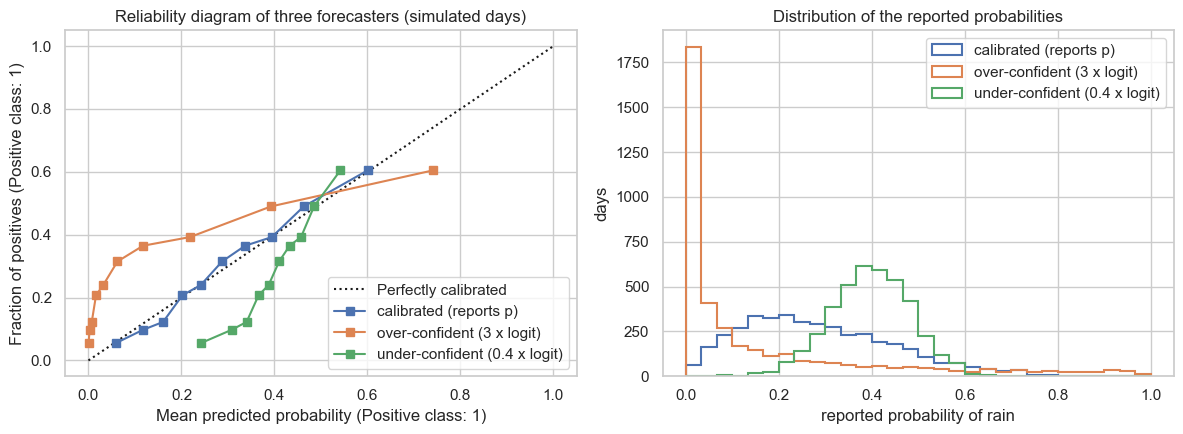

In [19]:
demo_rng = np.random.default_rng(1)
n_days = 4000
p_rain = demo_rng.beta(2, 5, size=n_days)                 # true probability of rain on each day
rain = (demo_rng.random(n_days) < p_rain).astype(int)     # what actually happened
logit_rain = np.log(p_rain / (1 - p_rain))

forecasters = {
    "calibrated (reports p)": p_rain,
    "over-confident (3 x logit)": 1 / (1 + np.exp(-3 * logit_rain)),
    "under-confident (0.4 x logit)": 1 / (1 + np.exp(-0.4 * logit_rain)),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, q in forecasters.items():
    CalibrationDisplay.from_predictions(rain, q, n_bins=10, strategy="quantile", name=name, ax=axes[0])
    axes[1].hist(q, bins=30, range=(0, 1), histtype="step", lw=1.5, label=name)
axes[0].set_title("Reliability diagram of three forecasters (simulated days)")
axes[1].set_title("Distribution of the reported probabilities")
axes[1].set_xlabel("reported probability of rain")
axes[1].set_ylabel("days")
axes[1].legend()
plt.tight_layout()

pd.DataFrame(
    {
        "ROC-AUC": {name: roc_auc_score(rain, q) for name, q in forecasters.items()},
        "Brier score": {name: brier_score_loss(rain, q) for name, q in forecasters.items()},
        "log-loss": {name: log_loss(rain, q) for name, q in forecasters.items()},
    }
)

Same ranking, identical ROC-AUC, very different probabilities: the over-confident forecaster lies below the diagonal at high probabilities and above it at low ones (an S-shape), the hedging one does the opposite. Only the proper scoring rules see the difference, and the calibrated forecaster wins on both of them. Any ranking metric is blind to this.

Models differ a lot in how calibrated they are out of the box:

- **logistic regression** is trained by minimising log-loss and is usually well calibrated,
- **random forests** average 0/1 votes and are typically *under-confident*: probabilities are pushed away from 0 and 1 because some trees always disagree (Niculescu-Mizil and Caruana, 2005),
- **boosted trees** are a mixed case: AdaBoost-style boosting (exponential loss) pushes probabilities *towards the middle* like an SVM, whereas gradient boosting with log-loss (XGBoost, LightGBM) is usually close to calibrated and becomes *over-confident* only when run for too many rounds; shallow **neural networks** were well calibrated in the 2005 study, modern deep networks are typically *over-confident* (Guo et al., 2017),
- any model trained with **class weights or resampling** is shifted away from the true probabilities on purpose.

Two standard post-hoc fixes learn a monotone mapping from scores to probabilities on held-out data: **Platt scaling** fits a logistic function to the scores (`method="sigmoid"`), **isotonic regression** fits a free-form non-decreasing step function (`method="isotonic"`, needs more data). `CalibratedClassifierCV` does this with internal cross-validation so that the calibration map is never fitted on the same rows as the model.

Below we compare the plain logistic regression, the same model trained with `class_weight="balanced"` (every positive counts as much as the five negatives), a random forest, and recalibrated versions of the latter two.

*Before running: which of the five curves will lie far below the diagonal, and why?*

,Brier score,log-loss,ROC-AUC
logistic regression,0.090,0.321,0.838
"logistic regression, class_weight=balanced",0.158,0.474,0.827
balanced logistic regression + Platt (sigmoid),0.097,0.329,0.830
random forest,0.103,0.347,0.817
random forest + isotonic,0.102,0.343,0.809


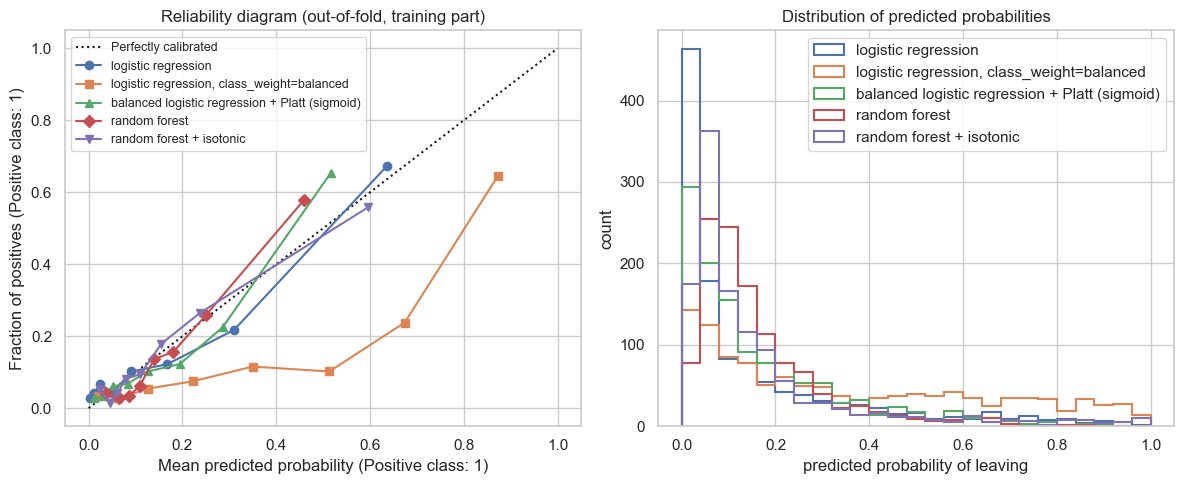

In [20]:
rf_plain = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=2, random_state=SEED))
logreg_balanced = make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))

calibration_models = {
    "logistic regression": logreg,
    "logistic regression, class_weight=balanced": logreg_balanced,
    "balanced logistic regression + Platt (sigmoid)": CalibratedClassifierCV(logreg_balanced, method="sigmoid", cv=3),
    "random forest": rf_plain,
    "random forest + isotonic": CalibratedClassifierCV(rf_plain, method="isotonic", cv=3),
}

calibration_probs = {}
for name, model in calibration_models.items():
    calibration_probs[name] = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for (name, prob), marker in zip(calibration_probs.items(), ["o", "s", "^", "D", "v"]):
    CalibrationDisplay.from_predictions(y_train, prob, n_bins=8, strategy="quantile", name=name, ax=axes[0], marker=marker)
    axes[1].hist(prob, bins=25, range=(0, 1), histtype="step", lw=1.5, label=name)
axes[0].set_title("Reliability diagram (out-of-fold, training part)")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].set_title("Distribution of predicted probabilities")
axes[1].set_xlabel("predicted probability of leaving")
axes[1].set_ylabel("count")
axes[1].legend()
plt.tight_layout()

pd.DataFrame(
    {
        "Brier score": {n: brier_score_loss(y_train, p) for n, p in calibration_probs.items()},
        "log-loss": {n: log_loss(y_train, p) for n, p in calibration_probs.items()},
        "ROC-AUC": {n: roc_auc_score(y_train, p) for n, p in calibration_probs.items()},
    }
)

Three observations:

- The **class-weighted logistic regression** is the clear outlier: its curve lies far below the diagonal because weighting the positives five-fold pushes every probability upwards (its predictions spread over the whole range up to 1 although only 16 % of employees leave). The ranking is almost unchanged (ROC-AUC 0.827 against 0.838: the weights move the slopes a little, not only the intercept), but the Brier score and log-loss are much worse. Platt scaling repairs this almost completely, which is the standard remedy when a model trained with class weights, resampling or `scale_pos_weight` has to deliver usable probabilities.
- The **random forest** ranks the employees about as well as the logistic regression but its probabilities are compressed towards the middle (see the histogram: it rarely says "0.8"), the typical mild under-confidence of forests; on this data set the effect is small and isotonic regression changes the Brier score by only a few thousandths.
- A monotone recalibration never changes the ROC-AUC by more than the noise of the internal cross-validation; it only moves the probabilities, not their order.

Rule of thumb: when a decision depends on the *value* of $\hat p$ (costs, expected values, risk communication), check the reliability diagram and calibrate if needed; when only the ordering matters, do not bother.

## 5. Models on the attrition data

We now compare the model families on the same preprocessing pipeline and the same stratified 5-fold split of the training part, so that differences come from the models and not from the folds. To take the class imbalance into account at training time all models use a form of **class weighting**: `class_weight="balanced"` in scikit-learn, `scale_pos_weight` in XGBoost and `pos_weight` in the PyTorch loss. Weighting up-weights the positives in the loss, which raises recall at the default threshold; the flip side is that the probabilities are no longer calibrated (they are shifted upwards), which the log-loss and Brier columns will show.

### A neural network as a scikit-learn estimator

The last model is a small **multilayer perceptron** (MLP) written in PyTorch, the library used in the second notebook for images. The MLP is a stack of affine maps and non-linearities,

$$
h^{(1)} = \text{ReLU}(W^{(1)} x + b^{(1)}), \qquad h^{(2)} = \text{ReLU}(W^{(2)} h^{(1)} + b^{(2)}), \qquad z = w^{(3)\top} h^{(2)} + b^{(3)}, \qquad \hat p = \sigma(z),
$$

trained by minimising the (weighted) binary cross-entropy with a stochastic gradient method. The ingredients of every PyTorch training loop appear in the class below and return in the second notebook:

- `Dataset` / `DataLoader`: shuffle the training rows and serve them in **mini-batches**,
- `nn.Module` (here `nn.Sequential`): the model as a composition of layers,
- the loss (`BCEWithLogitsLoss`, numerically stable sigmoid + cross-entropy; `pos_weight` handles the imbalance),
- the optimiser (`Adam`) and the three-step update `zero_grad()`, `loss.backward()`, `optimizer.step()`,
- **epochs** over the data with a validation check after each one and **early stopping**: training stops when the validation loss has not improved for `patience` epochs and the best weights are restored.

Wrapping all this in a class with `fit` / `predict_proba` / `predict` makes the network a drop-in replacement for any scikit-learn classifier, so it can go through the same `Pipeline` and the same cross-validation as the other models.

![A multilayer perceptron](https://raw.githubusercontent.com/francji1/01ADS/main/lectures/L04_classification_nn_tl/pics/NNet.png)

In [21]:
class TorchMLPClassifier(BaseEstimator, ClassifierMixin):
    '''Binary MLP classifier (PyTorch) with early stopping, usable inside scikit-learn pipelines.'''

    def __init__(self, hidden=(64, 32), dropout=0.2, lr=1e-3, weight_decay=1e-4, batch_size=64,
                 max_epochs=200, patience=15, val_fraction=0.15, pos_weight=True, random_state=SEED):
        self.hidden = hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_fraction = val_fraction
        self.pos_weight = pos_weight
        self.random_state = random_state

    def _build(self, n_features):
        layers, width = [], n_features
        for units in self.hidden:
            layers += [nn.Linear(width, units), nn.ReLU(), nn.Dropout(self.dropout)]
            width = units
        layers.append(nn.Linear(width, 1))
        return nn.Sequential(*layers)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        self.classes_ = np.array([0, 1])
        torch.manual_seed(self.random_state)

        # internal validation split (stratified) used only for early stopping
        X_fit, X_val, y_fit, y_val = train_test_split(
            X, y, test_size=self.val_fraction, stratify=y, random_state=self.random_state
        )
        loader = DataLoader(
            TensorDataset(torch.from_numpy(X_fit), torch.from_numpy(y_fit)),
            batch_size=self.batch_size, shuffle=True,
            generator=torch.Generator().manual_seed(self.random_state),
        )
        X_val_t, y_val_t = torch.from_numpy(X_val), torch.from_numpy(y_val)

        self.model_ = self._build(X.shape[1])
        pos_weight = torch.tensor([(y_fit == 0).sum() / max((y_fit == 1).sum(), 1)]) if self.pos_weight else None
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        self.history_ = {"train_loss": [], "val_loss": []}
        best_loss, best_state, epochs_without_improvement = np.inf, None, 0
        for epoch in range(self.max_epochs):
            self.model_.train()
            running = 0.0
            for xb, yb in loader:
                optimizer.zero_grad()
                loss = criterion(self.model_(xb).squeeze(1), yb)
                loss.backward()
                optimizer.step()
                running += loss.item() * len(xb)
            self.model_.eval()
            with torch.no_grad():
                val_loss = criterion(self.model_(X_val_t).squeeze(1), y_val_t).item()
            self.history_["train_loss"].append(running / len(X_fit))
            self.history_["val_loss"].append(val_loss)
            if val_loss < best_loss - 1e-4:
                best_loss, epochs_without_improvement = val_loss, 0
                best_state = {k: v.clone() for k, v in self.model_.state_dict().items()}
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement >= self.patience:
                    break
        self.model_.load_state_dict(best_state)
        self.n_epochs_ = len(self.history_["train_loss"])
        self.best_epoch_ = int(np.argmin(self.history_["val_loss"])) + 1
        return self

    def predict_proba(self, X):
        self.model_.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.model_(torch.from_numpy(np.asarray(X, dtype=np.float32))).squeeze(1)).numpy()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

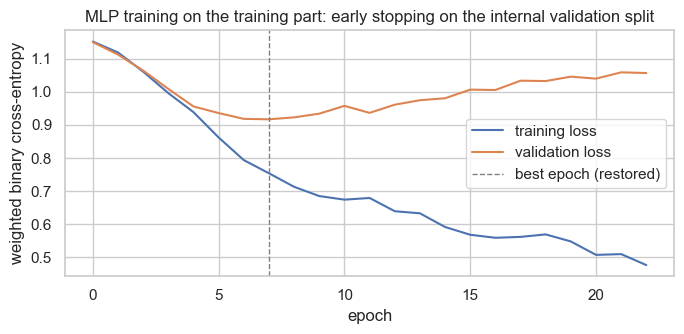

In [22]:
mlp_demo = make_pipeline(TorchMLPClassifier()).fit(X_train, y_train)
history = mlp_demo.named_steps["model"].history_

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history["train_loss"], label="training loss")
ax.plot(history["val_loss"], label="validation loss")
ax.axvline(mlp_demo.named_steps["model"].best_epoch_ - 1, color="grey", ls="--", lw=1, label="best epoch (restored)")
ax.set_xlabel("epoch")
ax.set_ylabel("weighted binary cross-entropy")
ax.set_title("MLP training on the training part: early stopping on the internal validation split")
ax.legend()
plt.tight_layout()

The validation loss stops improving long before the training loss does; without early stopping the network would keep fitting noise, the tabular equivalent of the overfitted decision tree of Lecture 03.

### Cross-validated comparison

The helper below does what `cross_validate` does, fold by fold, and additionally keeps the **out-of-fold probabilities** of every model so that we can draw pooled ROC/PR curves and tune thresholds afterwards without refitting.

*Before running: which model wins on PR-AUC, and by how much?*

In [23]:
ratio = float((y_train == 0).sum() / (y_train == 1).sum())  # negatives per positive

models = {
    "prevalence baseline": DummyClassifier(strategy="prior"),  # constant probability = prevalence, same decisions as the majority class
    "logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEED),
    "random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=2, random_state=SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=ratio, tree_method="hist", n_jobs=2, random_state=SEED, eval_metric="logloss",
    ),
    "PyTorch MLP": TorchMLPClassifier(),
}


def evaluate_cv(model, X, y, cv):
    # fit `model` on each fold, return per-fold metrics and the out-of-fold probabilities
    oof = np.zeros(len(y))
    rows = []
    for fold, (fit_idx, val_idx) in enumerate(cv.split(X, y)):
        start = time.perf_counter()
        estimator = clone(model).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        fit_time = time.perf_counter() - start
        prob = estimator.predict_proba(X.iloc[val_idx])[:, 1]
        oof[val_idx] = prob
        y_val = y.iloc[val_idx]
        rows.append(
            {
                "fold": fold,
                "ROC-AUC": roc_auc_score(y_val, prob),
                "PR-AUC": average_precision_score(y_val, prob),
                "F1 @ 0.5": f1_score(y_val, prob >= 0.5),
                "log-loss": log_loss(y_val, prob),
                "Brier": brier_score_loss(y_val, prob),
                "fit time [s]": fit_time,
            }
        )
    return oof, pd.DataFrame(rows).set_index("fold")


oof_probs, fold_scores = {}, {}
for name, model in models.items():
    oof_probs[name], fold_scores[name] = evaluate_cv(make_pipeline(model), X_train, y_train, cv)

summary = pd.DataFrame({name: scores.mean() for name, scores in fold_scores.items()}).T
summary_std = pd.DataFrame({name: scores.std() for name, scores in fold_scores.items()}).T
summary.sort_values("PR-AUC", ascending=False)

,ROC-AUC,PR-AUC,F1 @ 0.5,log-loss,Brier,fit time [s]
PyTorch MLP,0.827,0.627,0.520,0.453,0.146,0.766
logistic regression,0.827,0.606,0.492,0.474,0.158,0.029
XGBoost,0.814,0.603,0.537,0.365,0.111,0.126
random forest,0.807,0.562,0.362,0.357,0.106,0.500
decision tree (depth 4),0.677,0.334,0.410,1.026,0.188,0.011
prevalence baseline,0.500,0.162,0.000,0.442,0.135,0.007


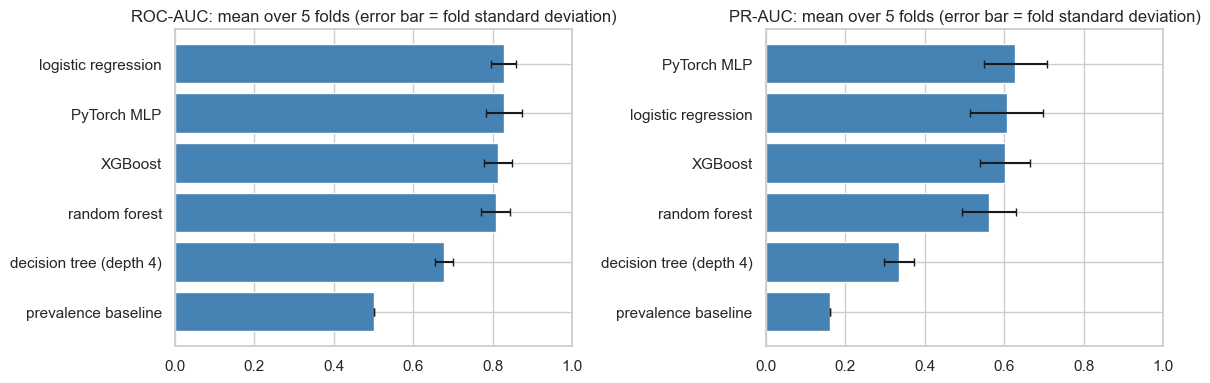

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    order = summary[metric].sort_values().index
    ax.barh(order, summary.loc[order, metric], xerr=summary_std.loc[order, metric], color="steelblue", capsize=3)
    ax.set_title(f"{metric}: mean over 5 folds (error bar = fold standard deviation)")
    ax.set_xlim(0, 1)
plt.tight_layout()

On this small, mostly linear data set the four main models (MLP, logistic regression, XGBoost, random forest) are within one fold-standard-deviation of each other on both ROC-AUC and PR-AUC; nothing beats the linear model convincingly, and the single tree is clearly worse. The MLP ends up on par with the ensembles, a typical outcome on a 1 000-row table: there is simply not enough data for a network to learn more than a logistic regression already captures. Note the effect of class weighting in the probability columns: the weighted logistic regression and the MLP (`pos_weight`) have far *worse* log-loss and Brier scores than the unweighted logistic regression of Section 4 (0.32 and 0.09), because their probabilities are deliberately shifted upwards; `balanced_subsample` in the forest and `scale_pos_weight` in XGBoost distort less.

The curves below pool the out-of-fold probabilities of the five fold models into one ranking, which is a convenient picture but a slightly different number: a model whose folds score on different scales (the MLP, whose early stopping ends at a different epoch in every fold) is penalised by pooling, so its pooled AP in the legend (0.59) is lower than the mean of its per-fold APs in the table (0.63). The table is the estimate, the curves are the illustration.

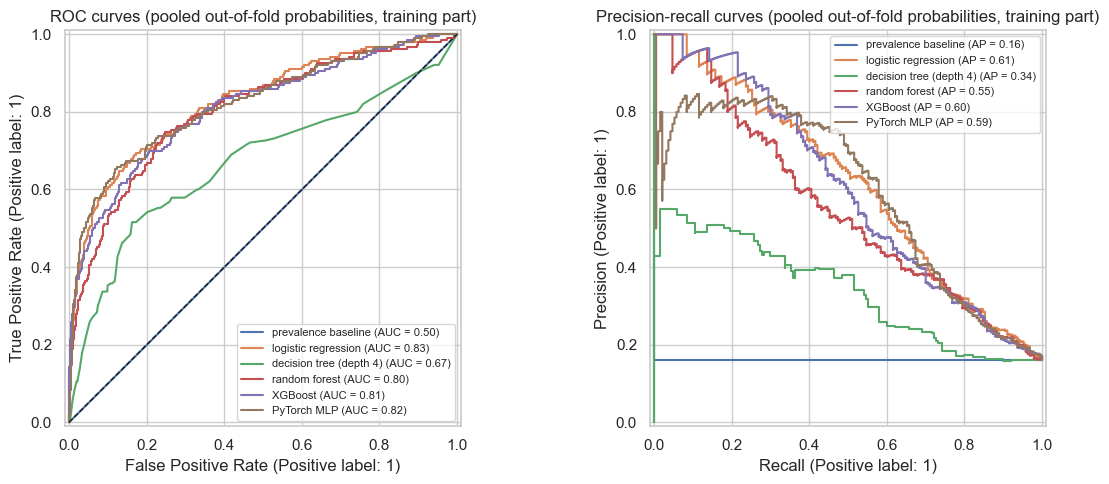

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in oof_probs.items():
    RocCurveDisplay.from_predictions(y_train, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_train, prob, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves (pooled out-of-fold probabilities, training part)")
axes[1].set_title("Precision-recall curves (pooled out-of-fold probabilities, training part)")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()

### Threshold tuning and the final check on the test set

For each model the threshold that maximises $F_1$ is chosen on the out-of-fold probabilities. Only now the models are refitted on the whole training part and evaluated **once** on the test part at that threshold. The test numbers are a single realisation on 294 rows (47 positives), so differences of a few hundredths are noise; the cross-validated table above is the more reliable guide.

Compare the tuned thresholds with Section 3: for the unweighted logistic regression the $F_1$-optimal threshold was *below* 0.5 (0.37); for the class-weighted logistic regression, the MLP and XGBoost it is *above* 0.5 because weighting pushed their probabilities upwards. The random forest with `balanced_subsample` is the exception (0.30): its probabilities stay compressed towards the middle, as the reliability diagram of Section 4 showed. Weighting and threshold tuning are two ways of moving the same decision boundary; combining both without looking at the probabilities over-corrects.

In [26]:
test_rows = []
fitted = {}
for name, model in models.items():
    t = best_threshold(y_train, oof_probs[name], "f1") if name != "prevalence baseline" else 0.5
    fitted[name] = make_pipeline(model).fit(X_train, y_train)
    prob_test = fitted[name].predict_proba(X_test)[:, 1]
    pred_test = prob_test >= t
    test_rows.append(
        {
            "model": name,
            "tuned threshold": t,
            "test ROC-AUC": roc_auc_score(y_test, prob_test),
            "test PR-AUC": average_precision_score(y_test, prob_test),
            "test precision": precision_score(y_test, pred_test, zero_division=0),
            "test recall": recall_score(y_test, pred_test),
            "test F1": f1_score(y_test, pred_test),
            "test balanced acc.": balanced_accuracy_score(y_test, pred_test),
        }
    )
test_summary = pd.DataFrame(test_rows).set_index("model").sort_values("test PR-AUC", ascending=False)
test_summary

,tuned threshold,test ROC-AUC,test PR-AUC,test precision,test recall,test F1,test balanced acc.
model,,,,,,,
logistic regression,0.724,0.803,0.561,0.538,0.447,0.488,0.687
PyTorch MLP,0.682,0.800,0.556,0.533,0.511,0.522,0.713
XGBoost,0.563,0.776,0.519,0.474,0.383,0.424,0.651
random forest,0.301,0.792,0.451,0.444,0.511,0.475,0.695
decision tree (depth 4),0.541,0.697,0.335,0.301,0.532,0.385,0.649
prevalence baseline,0.500,0.500,0.160,0.000,0.000,0.000,0.500


### What drives attrition: the logistic regression coefficients

A linear model offers something the ensembles do not: a direct reading of the effect of each feature. With standardised numeric features, $e^{\beta_j}$ is the multiplicative change of the **odds** of leaving for a one-standard-deviation increase of feature $j$; for a one-hot encoded category the coefficient is relative to an average category of the same variable (all dummies are kept, the $L_2$ penalty makes them identifiable), and the odds ratio between two categories $a$ and $b$ is $e^{\beta_a - \beta_b}$, e.g. laboratory technician vs. research director $e^{1.19 + 1.47} \approx 14$. The coefficients below are those of the class-weighted logistic regression of Section 5, refitted on the whole training part; weighting mainly shifts the intercept, the slopes change little.

,coefficient,odds ratio
JobRole_Research Director,-1.466,0.231
JobRole_Laboratory Technician,1.194,3.301
JobRole_Sales Representative,1.121,3.067
BusinessTravel_Non-Travel,-0.994,0.370
OverTime_No,-0.893,0.410
EducationField_Other,-0.798,0.450
BusinessTravel_Travel_Frequently,0.788,2.198
OverTime_Yes,0.762,2.142
EducationField_Human Resources,0.721,2.057
JobRole_Healthcare Representative,-0.647,0.524


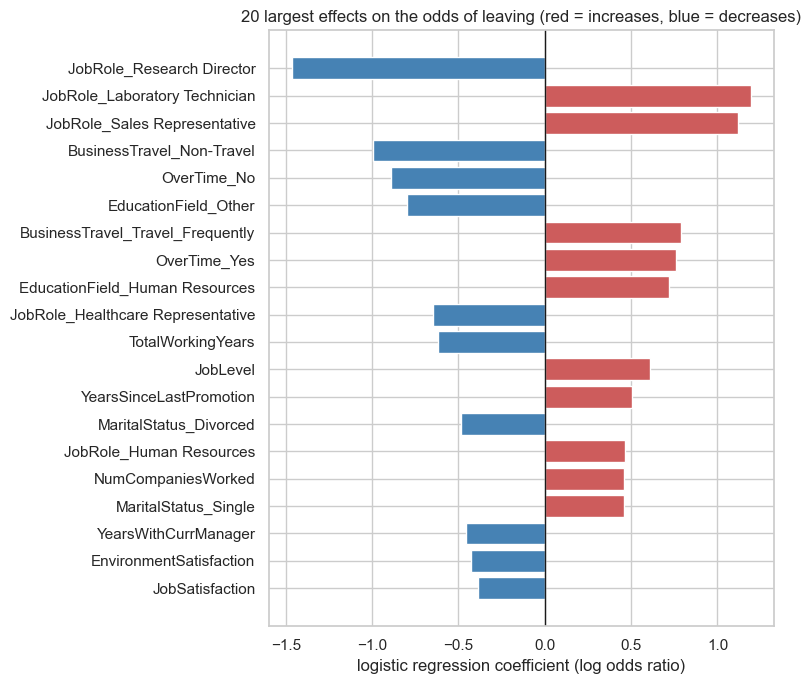

In [27]:
logreg_full = fitted["logistic regression"]
feature_names = [name.split("__", 1)[-1] for name in logreg_full.named_steps["prep"].get_feature_names_out()]   # drop the num__/cat__ prefixes
coefficients = pd.Series(logreg_full.named_steps["model"].coef_[0], index=feature_names)
effects = pd.DataFrame({"coefficient": coefficients, "odds ratio": np.exp(coefficients)})
effects = effects.reindex(effects["coefficient"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 7))
top = effects.head(20).iloc[::-1]
ax.barh(top.index, top["coefficient"], color=np.where(top["coefficient"] > 0, "indianred", "steelblue"))
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("logistic regression coefficient (log odds ratio)")
ax.set_title("20 largest effects on the odds of leaving (red = increases, blue = decreases)")
plt.tight_layout()
effects.head(10)

Job role dominates (laboratory technicians and sales representatives leave more often, research directors and healthcare representatives less), followed by overtime, frequent business travel, years since the last promotion, the number of previous employers and being single; total working years and years with the current manager decrease the odds. The positive sign of `JobLevel` next to the negative sign of `TotalWorkingYears` is a reminder that coefficients are *conditional* effects: the two features are strongly correlated and share their effect between them. All of this describes associations in observational data, not causes.

### SHAP values: the same question for the non-linear model

A gradient-boosting model has no coefficients, but **SHAP values** (Lecture 03) give every single prediction an additive
decomposition: the model's log-odds for one employee equal a base value (the average log-odds over the training
part) plus one contribution per feature. The **beeswarm** plot shows these contributions for all employees at once,
one row per feature, coloured by the feature value: it is the non-linear counterpart of the coefficient plot above,
with the difference that the same feature can push in both directions depending on the other features. The
**waterfall** plot explains one employee.

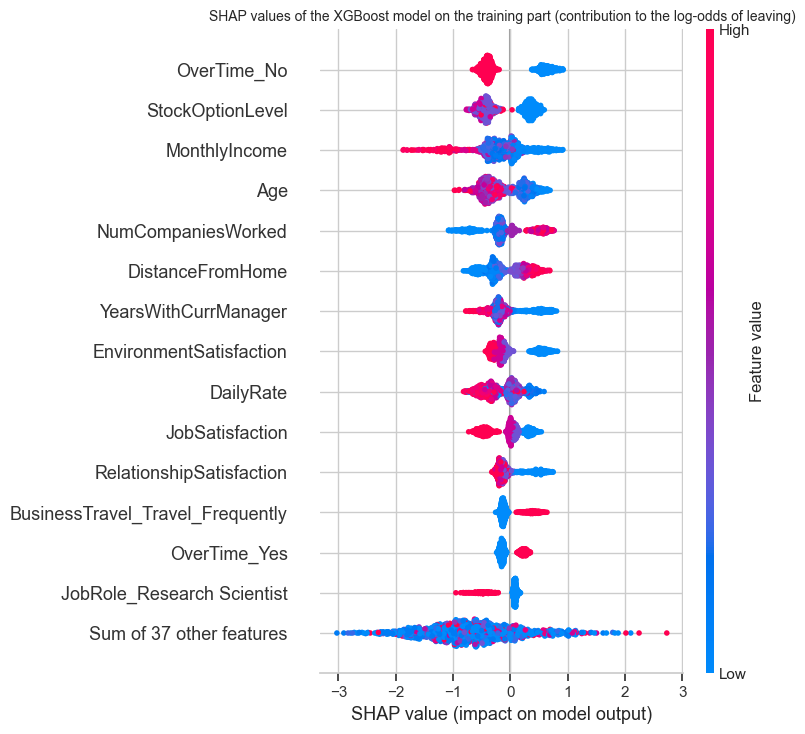

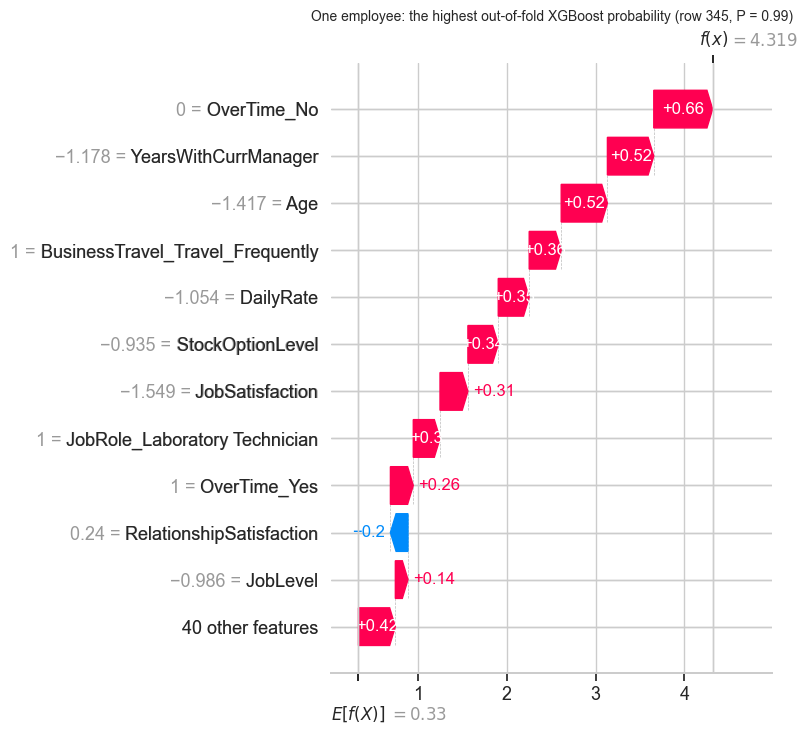

In [28]:
import shap

xgb_pipeline = fitted["XGBoost"]
prep_names = [name.split("__", 1)[-1] for name in xgb_pipeline.named_steps["prep"].get_feature_names_out()]
X_train_prep = pd.DataFrame(xgb_pipeline.named_steps["prep"].transform(X_train), columns=prep_names)
explainer = shap.TreeExplainer(xgb_pipeline.named_steps["model"])
shap_values = explainer(X_train_prep)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.gcf().axes[0].set_title("SHAP values of the XGBoost model on the training part (contribution to the log-odds of leaving)", fontsize=10)
plt.tight_layout()
plt.show()

who = int(np.argmax(oof_probs["XGBoost"]))
shap.plots.waterfall(shap_values[who], max_display=12, show=False)
plt.gcf().axes[0].set_title(f"One employee: the highest out-of-fold XGBoost probability (row {who}, P = {oof_probs['XGBoost'][who]:.2f})", fontsize=10)
plt.tight_layout()

The beeswarm tells the same story as the coefficients, with more nuance: working overtime (`OverTime_No` = 0, red on
the right), no stock options, a low monthly income, young age, many previous employers, a long commute, a short time
with the current manager, low environment, job and relationship satisfaction and frequent business travel all push
towards leaving; research scientists tend to stay. The width of the swarm shows how unevenly a feature matters: a
low monthly income can add up to two units of log-odds for a few employees, while for most it changes little, which
is a non-linearity a coefficient cannot express. (The one-hot encoding keeps both `OverTime_No` and `OverTime_Yes`,
so the overtime effect is split between the two rows.) The waterfall for the employee with the highest out-of-fold
probability stacks exactly these factors: overtime, a new manager, young age, frequent travel, no stock options and
low job satisfaction, each adding a few tenths to the log-odds, from the base value to a probability close to one.
SHAP explains the *model*; whether the features cause attrition is a different question that these data cannot
answer.

## 6. Which model when

This section is a reference to read after the lecture; in the session we only summarise it in a few sentences.

| | Logistic regression | Decision tree | Random forest | Gradient boosting (XGBoost, LightGBM, CatBoost) | Neural network (MLP) |
|---|---|---|---|---|---|
| **data size** | any; shines with few rows | small to medium | medium | medium to large | large (10⁴–10⁶ rows and up) |
| **feature types** | needs scaling and one-hot; linear effects only (add interactions / splines by hand) | mixed, no scaling | mixed, no scaling | mixed, no scaling, native categories (CatBoost, LightGBM) | numeric only (scale!), categories via embeddings |
| **missing values** | impute | native (scikit-learn ≥ 1.3) | native (scikit-learn ≥ 1.4) | native (XGBoost, LightGBM, CatBoost, HistGradientBoosting) | impute |
| **non-linearity, interactions** | no | yes | yes | yes | yes |
| **interpretability** | coefficients, odds ratios | the tree itself | feature importance, SHAP | feature importance, SHAP | hard |
| **calibration out of the box** | good | poor (piecewise constant) | under-confident | close with log-loss, over-confident when over-trained | over-confident (deep nets) |
| **training cost** | seconds | seconds | minutes, parallel | minutes, often the accuracy winner on tabular data | minutes to hours, GPU |
| **tuning effort** | low ($C$) | low (depth) | low | medium to high (learning rate, depth, regularisation, early stopping) | high (architecture, learning rate, regularisation, schedule) |
| **typical use** | baseline, regulated settings, small data | explanation, rules | robust default | competitions, production tabular models | images, text, audio, very large tables, multi-task and multimodal inputs |

Practical recommendations for tabular data:

1. Always start with a **dummy baseline** and a **logistic regression** inside a pipeline; they take seconds and give the scale for everything else.
2. Compare with cross-validation on a metric that matches the use case (PR-AUC or cost on imbalanced data), not with a single train/test split and not with accuracy.
3. **Gradient boosting** is the usual accuracy winner on tabular data; random forests are the robust default when there is no time to tune.
4. Neural networks win when the inputs are images, text or audio, when the data are huge, or when several inputs/outputs must be learned jointly. That is the subject of the second notebook.
5. Decide the **threshold** on validation predictions from the costs of the two error types, and **calibrate** when the probabilities are used as probabilities.

### Multiclass problems in one paragraph

With $K > 2$ classes the output is a probability vector from a **softmax** layer (or from a one-vs-rest set of binary classifiers), the loss is the categorical cross-entropy, and the confusion matrix is $K \times K$. Precision, recall and $F_1$ are computed per class and summarised as **macro** (mean over classes, every class equally important), **weighted** (by class size) or **micro** (pooled counts) averages; ROC-AUC and average precision are likewise averaged one-vs-rest. Everything about thresholds becomes a question of per-class costs or of calibrating the whole probability vector.

A small example with ten classes: the handwritten digits of scikit-learn (1 797 images of 8×8 pixels), classified by a multinomial logistic regression with 5-fold cross-validation.

In [29]:
from sklearn.datasets import load_digits

digits = load_digits()
digit_model = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=2000))])
digit_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pred_digits = cross_val_predict(digit_model, digits.data, digits.target, cv=digit_cv)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, label in zip(axes, range(10)):
    ax.imshow(digits.images[digits.target == label][0], cmap="gray_r")
    ax.set_title(str(label), fontsize=10)
    ax.axis("off")
fig.suptitle("One example of each class (8×8 pixels)", y=1.15)

fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay.from_predictions(digits.target, pred_digits, cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"10 × 10 confusion matrix (out-of-fold), accuracy {accuracy_score(digits.target, pred_digits):.3f}")
plt.tight_layout()

print(classification_report(digits.target, pred_digits, digits=3))

              precision    recall  f1-score   support

           0      0.994     1.000     0.997       178
           1      0.941     0.967     0.954       182
           2      0.983     0.989     0.986       177
           3      0.972     0.962     0.967       183
           4      0.983     0.978     0.981       181
           5      0.961     0.951     0.956       182
           6      0.989     0.983     0.986       181
           7      0.989     0.989     0.989       179
           8      0.932     0.943     0.937       174
           9      0.966     0.950     0.958       180

    accuracy                          0.971      1797
   macro avg      0.971     0.971     0.971      1797
weighted avg      0.971     0.971     0.971      1797



The diagonal holds almost everything; the off-diagonal cells show which pairs the model confuses (here mainly 1 ↔ 8 and 5 ↔ 9, then 3, 8 and 9 among each other: digits that share strokes at 8×8 resolution). With ten balanced classes the macro and weighted averages coincide and are close to the accuracy; with imbalanced classes the macro average would expose a class that the model neglects, which the accuracy hides, exactly as in the binary case.

## 7. Summary

- A classifier produces **scores → probabilities → decisions**; rank quality (ROC-AUC, PR-AUC), probability quality (log-loss, Brier, reliability diagram) and decision quality (confusion matrix metrics at a threshold) are evaluated separately.
- Learn the vocabulary: recall = sensitivity = TPR = power, precision = PPV, specificity = TNR, FPR = type I error rate, FNR = type II error rate.
- On imbalanced data accuracy is misleading; use PR-AUC, balanced accuracy, MCC and explicit costs.
- The default threshold 0.5 is a convention, not a recommendation; tune it on out-of-fold predictions.
- Class weighting improves recall but distorts probabilities; recalibrate if the probabilities matter.
- On tabular data compare linear models, forests and boosting with the same pipeline and the same folds; on images and text, neural networks take over.

### Further reading

- scikit-learn user guide, *Metrics and scoring: quantifying the quality of predictions* and *Probability calibration*.
- T. Saito, M. Rehmsmeier (2015), *The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets*, PLoS ONE 10(3).
- A. Niculescu-Mizil, R. Caruana (2005), *Predicting good probabilities with supervised learning*, ICML.
- C. Guo, G. Pleiss, Y. Sun, K. Q. Weinberger (2017), *On calibration of modern neural networks*, ICML.
- D. Chicco, G. Jurman (2020), *The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation*, BMC Genomics 21.
- T. Fawcett (2006), *An introduction to ROC analysis*, Pattern Recognition Letters 27.